In [1]:
import os

# Use conda's newer libstdc++ instead of the system one
conda_lib = os.path.expanduser("~/.conda/envs/hnn-core-env/lib")
ld_path = os.environ.get("LD_LIBRARY_PATH", "")
os.environ["LD_LIBRARY_PATH"] = f"{conda_lib}:{ld_path}"

# UCX settings (from before)
os.environ["UCX_TLS"] = "tcp,self,sm"
os.environ["UCX_NET_DEVICES"] = "all"


# MPI paths
mpi_bin = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin"
mpi_lib = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/lib"
if mpi_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{mpi_bin}:{os.environ['PATH']}"
if mpi_lib not in ld_path:
    os.environ["LD_LIBRARY_PATH"] = f"{mpi_lib}:{os.environ['LD_LIBRARY_PATH']}"

In [2]:
import sys
# Add MPI bin directory to PATH
mpi_bin = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin"
if mpi_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{mpi_bin}:{os.environ['PATH']}"

# print("Updated PATH to include MPI")
# print("MPI location:", mpi_bin)

import os
print("PATH:", os.environ.get('PATH', 'NOT SET'))
print("Which mpiexec:")
import subprocess
result = subprocess.run(['which', 'mpiexec'], capture_output=True, text=True)
print(result.stdout if result.returncode == 0 else "mpiexec not found")

PATH: /oscar/rt/sw/external/hpcx-mpi/2.25.1/bin:/users/kduecker/.conda/envs/hnn-core-env/bin:/oscar/rt/9.6/25/x86_64_v3/code-server-4.96.4-2mbqypo7726gva5cbeogfppy2doijdhq/lib/vscode/bin/remote-cli:/users/kduecker/bin:/oscar/runtime/bin:/oscar/rt/9.6/25/spack/x86_64_v3/code-server-4.96.4-2mbqypo7726gva5cbeogfppy2doijdhq/bin:/users/kduecker/.conda/envs/hnn-core-env/bin:/oscar/rt/9.6/25/x86_64_v3/miniforge3-25.3.0-3-a6hhdjzejtacz63sugjqnvgosfqz63ul/condabin:/users/kduecker/bin:/usr/local/bin:/usr/bin:/usr/local/sbin:/usr/sbin:/usr/lpp/mmfs/bin:/usr/lpp/mmfs/sbin:/users/kduecker/bin
Which mpiexec:
/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin/mpiexec



In [3]:
import os
import os.path as op

import matplotlib.pyplot as plt
import pickle

from hnn_core.hnn_io import write_network_configuration, read_network_configuration
from hnn_core.dipole import average_dipoles
from hnn_core.dipole import _rmse, average_dipoles

import sys

pth = '/users/kduecker/hnn-tuning/'
sys.path.append(pth)
#
sys.path.append(op.join(pth, 'utils'))
from general_plot_utils import assign_color
import hnn_core
from hnn_core.params import _short_name

from hnn_core import duecker_ET_model, simulate_dipole, read_dipole, MPIBackend, jones_2009_model

from hnn_core.optimization import Optimizer
import numpy as np
hnn_core_root = op.join(op.dirname(hnn_core.__file__))
pathfig = op.join(pth, 'new_model_HNN/figures')

# The number of cores may need modifying depending on your current machine.
cols = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
plt.rcParams['pdf.fonttype'] = 'truetype'
import matplotlib

col_lines = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
cmap_lines = matplotlib.colors.ListedColormap(col_lines)
# Set global font sizes
plt.rcParams['font.size'] = 12          # Default text size
plt.rcParams['axes.titlesize'] = 12      # Title size
plt.rcParams['axes.labelsize'] = 12      # Axis labels (xlabel, ylabel)
plt.rcParams['xtick.labelsize'] = 12    # X-axis tick labels
plt.rcParams['ytick.labelsize'] = 12     # Y-axis tick labels
plt.rcParams['legend.fontsize'] = 12     # Legend text

n_procs=3
cm_neurons = np.array([[218,166,156], [164,30,79], [119,161,187],[92,114,183]])/255

--No graphics will be displayed.


In [4]:
exp_dpl = read_dipole(op.join(pth, 'hnn-data/MEG_detection_data/S1_SupraT.txt'))

tstop = exp_dpl.times[-1]
scale_factor = 1000
smooth_window_len = 5

In [5]:
def net_block_dend_ca(net, cell_type='L5ET'):

    sections = ['apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
    for sec in sections:
        net.cell_types[cell_type]['cell_object'].sections[sec].mechs['Ca_HVA']['gbar_Ca_HVA'][1] = [0]*len(net.cell_types[cell_type]['cell_object'].sections[sec].mechs['Ca_HVA']['gbar_Ca_HVA'][1])
        net.cell_types[cell_type]['cell_object'].sections[sec].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1] = [0]*len(net.cell_types[cell_type]['cell_object'].sections[sec].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1])

    return net

In [6]:
np.log10(0.01)

np.float64(-2.0)

In [7]:
net = duecker_ET_model()
net.set_cell_positions(inplane_distance=30.)
depths = list(list(range(0,2000,100)))
electrode_pos = [(135, 135, dep) for dep in depths]
net.add_electrode_array('probe1', electrode_pos)
weights_ampa_p1 = {'L2_basket': 0.01, 
                   'L2_pyramidal': 0.015,
                   'L5_basket': 0.0, 
                   'L5ET': 0.03}
weights_nmda_p1 = {'L2_basket': 0.01, 'L2_pyramidal': 0.05,
                   'L5_basket': 0.0, 'L5ET': .025}
synaptic_delays_prox = {'L2_basket': 0.1, 'L2_pyramidal': .1,
                        'L5_basket': 1, 'L5ET': 1}

net.add_evoked_drive('prox1', mu=18, sigma=2.5, numspikes=1, weights_ampa=weights_ampa_p1,
    weights_nmda=weights_nmda_p1, location='proximal', synaptic_delays=synaptic_delays_prox)

weights_ampa_d1 = {'L2_basket': 0.005, 'L2_pyramidal': 0.01, 'L5ET': 1.}
weights_nmda_d1 = {'L2_basket': 0.0, 'L2_pyramidal': .01, 'L5ET': 1.}
synaptic_delays_dist = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,'L5ET': 0.1}

net.add_evoked_drive('dist1', mu=62, sigma=5, numspikes=2, weights_ampa=weights_ampa_d1,
    weights_nmda=weights_nmda_d1, location='distal', synaptic_delays=synaptic_delays_dist)

weights_ampa_p2 = {'L2_basket': 0.01, 'L2_pyramidal':0.3,
                   'L5_basket': 0.001, 'L5ET': 0.3}
weights_nmda_p2 = {'L2_basket': 0.01, 'L2_pyramidal': 0.2,
                   'L5_basket': 0.001, 'L5ET': 0.2}
synaptic_delays_prox = {'L2_basket': 0.1, 'L2_pyramidal': .1,
                        'L5_basket': 1., 'L5ET': 1.}
net.add_evoked_drive('prox2', mu=100, sigma=15, numspikes=1, weights_ampa=weights_ampa_p2,
    weights_nmda=weights_nmda_p2, location='proximal', synaptic_delays=synaptic_delays_prox)


with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net, tstop=tstop, n_trials=1,bsl_cor='duecker')


MPI will run 1 trial(s) sequentially by distributing network neurons over 3 processes.
numprocs=3
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Applying calcium model baseline correction


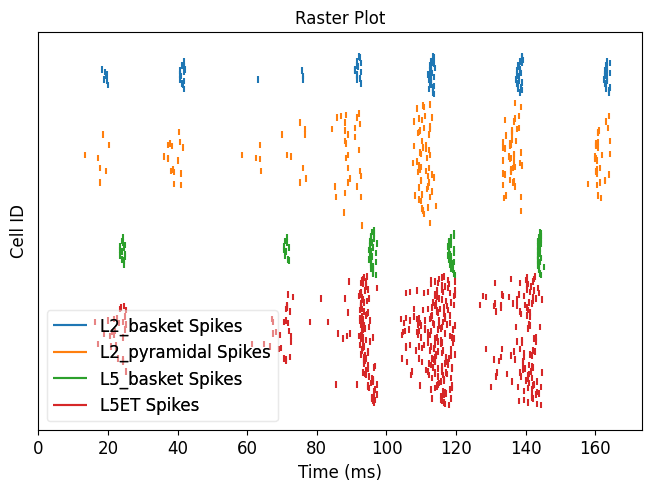

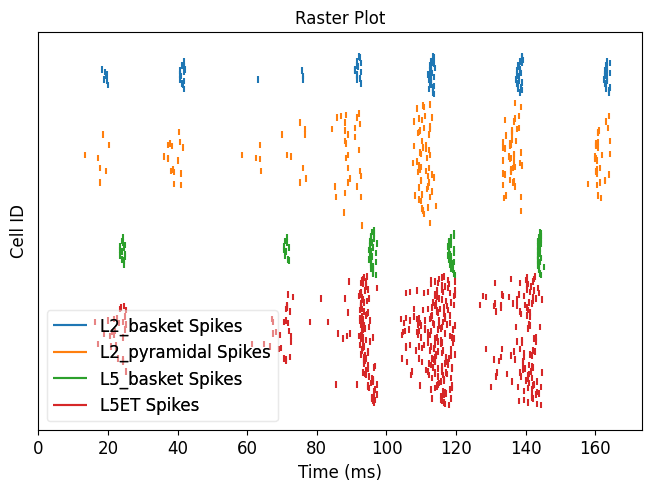

In [41]:

net.cell_response.plot_spikes_raster()


In [42]:
dpl = [d.scale(scale_factor) for d in dpl]
dpl = [d.smooth(smooth_window_len) for d in dpl]


In [43]:
avg_dpl = average_dipoles(dpl)

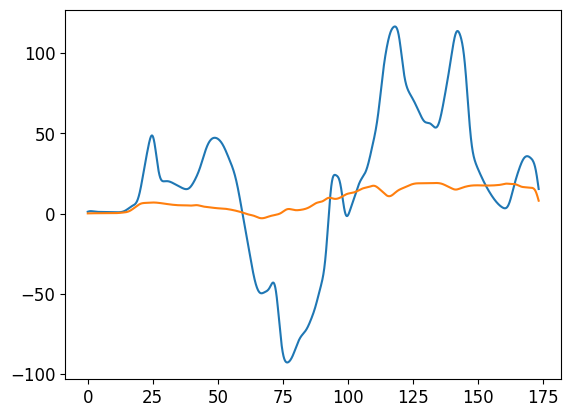

In [44]:
plt.plot(avg_dpl.times, avg_dpl.data['L5'])
plt.plot(avg_dpl.times, avg_dpl.data['L2'])

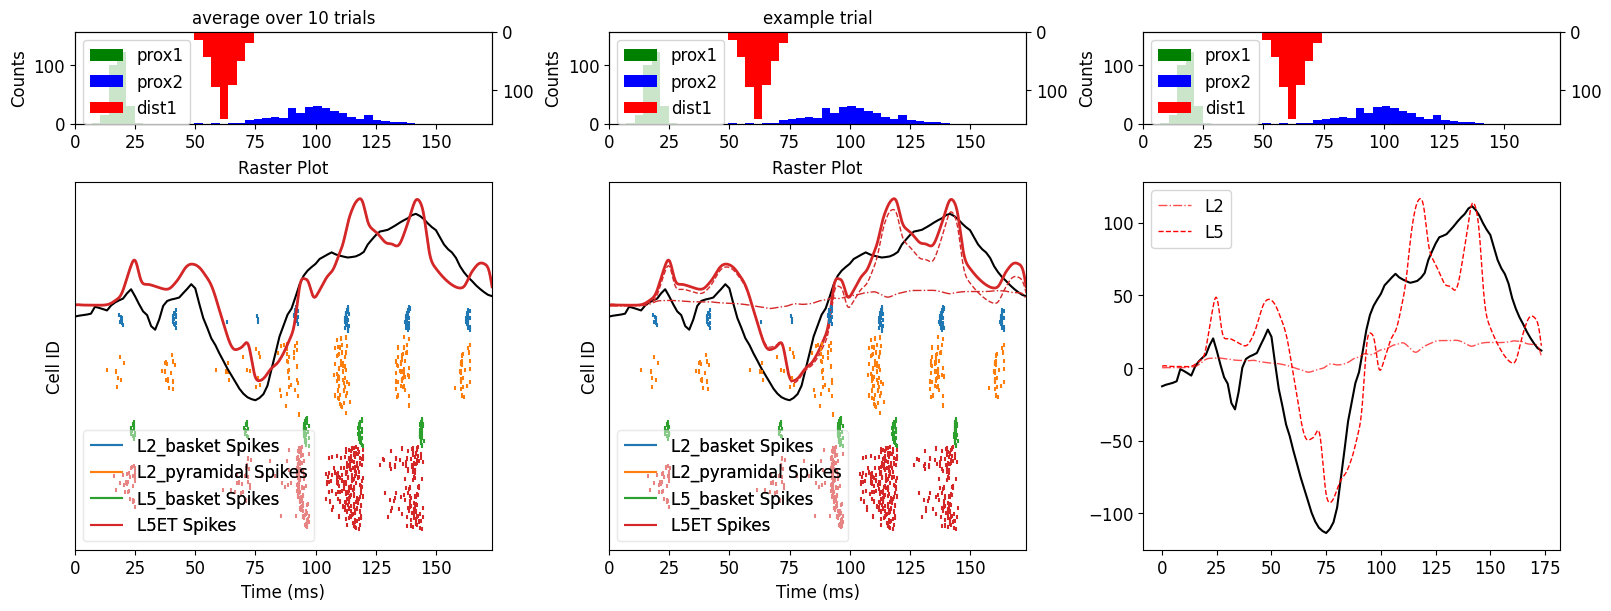

In [45]:
fig, ax = plt.subplots(2,3, figsize=(16,6), height_ratios=[0.25, 1], constrained_layout=True)

for i in range(3):
    net.cell_response.plot_spikes_hist(ax=ax[0,i], show=False, invert_spike_types='dist1')
net.cell_response.plot_spikes_raster(ax=ax[1,0], show=False)
for d in dpl:
    ax[1,0].plot(d.times, d.data['agg'], color='gray', alpha=0.3)

ax[1,0].plot(exp_dpl.times, exp_dpl.data['agg'], color='k')

ax[1,0].plot(avg_dpl.times, avg_dpl.data['agg'], linewidth=2, color='C3')

ax[1,1].plot(exp_dpl.times, exp_dpl.data['agg'], color='k')

ax[1,1].plot(dpl[0].times, dpl[0].data['agg'], linewidth=2, color='C3', label='agg')
ax[1,1].plot(dpl[0].times, dpl[0].data['L5'], linewidth=1, color='C3', linestyle='--', label='L5')
ax[1,1].plot(dpl[0].times, dpl[0].data['L2'], linewidth=1, color='C3', linestyle='-.', label='L2')
ax[1,1].legend()

ax[0,0].set_title('average over 10 trials')
ax[0,1].set_title('example trial')

net.cell_response.plot_spikes_raster(ax=ax[1,1], trial_idx=0, show=False)

#net.cell_response.plot_spikes_hist(ax=ax[0,2], show=False, invert_spike_types='dist1')
ax[1,2].plot(exp_dpl.times, exp_dpl.data['agg'], color='k')

ax[1,2].plot(dpl[0].times, dpl[0].data['L2'], linewidth=1, color='r', alpha=0.7, linestyle='-.', label='L2')
ax[1,2].plot(dpl[0].times, dpl[0].data['L5'], linewidth=1, color='r', label='L5', linestyle='--')
ax[1,2].legend()
fig.savefig(f'{pathfig}/handtuned_ERP.png')

In [13]:
net.connectivity

[L2_pyramidal -> L2_pyramidal
 cell counts: 100 srcs, 100 targets
 connection probability: 1.0 
 loc: 'proximal'; receptor: 'nmda'
 weight: 0.0002; delay: 1.0; lamtha: 6.125threshold: 0.0gain: 1.0
  ,
 L2_pyramidal -> L2_pyramidal
 cell counts: 100 srcs, 100 targets
 connection probability: 1.0 
 loc: 'proximal'; receptor: 'ampa'
 weight: 0.0002; delay: 1.0; lamtha: 6.125threshold: 0.0gain: 1.0
  ,
 L5ET -> L5ET
 cell counts: 100 srcs, 100 targets
 connection probability: 1.0 
 loc: 'proximal'; receptor: 'nmda'
 weight: 0.00065; delay: 1.0; lamtha: 6.125threshold: 0.0gain: 1.0
  ,
 L5ET -> L5ET
 cell counts: 100 srcs, 100 targets
 connection probability: 1.0 
 loc: 'proximal'; receptor: 'ampa'
 weight: 0.00065; delay: 1.0; lamtha: 6.125threshold: 0.0gain: 1.0
  ,
 L2_basket -> L2_pyramidal
 cell counts: 35 srcs, 100 targets
 connection probability: 1.0 
 loc: 'soma'; receptor: 'gabaa'
 weight: 0.1; delay: 1.0; lamtha: 6.125threshold: 0.0gain: 1.0
  ,
 L2_basket -> L2_pyramidal
 cell co

In [14]:
with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    dpl_dt = simulate_dipole(net, tstop=tstop, n_trials=5,dt=0.05, bsl_cor='duecker')

/oscar/home/kduecker/oscar-install/hnn-core/hnn_core/parallel_backends.py:912: UserWarning: Number of requested MPI processes exceeds available cores. Enabling MPI oversubscription automatically.
  warn(


MPI will run 5 trial(s) sequentially by distributing network neurons over 3 processes.
numprocs=3
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
[Done]
Trial 1: 0.05 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...


/oscar/home/kduecker/oscar-install/hnn-core/hnn_core/parallel_backends.py:213: UserWarning: Received KeyboardInterrupt. Stopping simulation process...
  warn("Received KeyboardInterrupt. Stopping simulation process...")


Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Building the NEURON model
[Done]
Trial 2: 0.05 ms...
Trial 2: 10.0 ms...
Trial 2: 20.0 ms...
Trial 2: 30.0 ms...
Trial 2: 40.0 ms...
Trial 2: 50.0 ms...
Trial 2: 60.0 ms...
Trial 2: 70.0 ms...
Trial 2: 80.0 ms...
Trial 2: 90.0 ms...
Trial 2: 100.0 ms...
Trial 2: 110.0 ms...
Trial 2: 120.0 ms...
Trial 2: 130.0 ms...
Trial 2: 140.0 ms...
Trial 2: 150.0 ms...
Trial 2: 160.0 ms...
Trial 2: 170.0 ms...
Building the NEURON model
[Done]
Trial 3: 0.05 ms...
Trial 3: 10.0 ms...
Trial 3: 20.0 ms...
Trial 3: 30.0 ms...
Trial 3: 40.0 ms...
Trial 3: 50.0 ms...
Trial 3: 60.0 ms...
Trial 3: 70.0 ms...
Trial 3: 80.0 ms...
Trial 3: 90.0 ms...
Trial 3: 100.0 ms...
Trial 3: 110.0 ms...
Trial 3: 120.0 ms...
Trial 3: 130.0 ms...
Trial 3: 140.0 ms...
Trial 3: 150.0 ms...
Trial 3: 160

RuntimeError: MPI simulation failed. Return code: -9

In [ ]:
dpl_dt = [d.scale(scale_factor) for d in dpl_dt]

In [ ]:
avg_dpl_dt = average_dipoles(dpl_dt)

plt.plot(avg_dpl_dt.times, avg_dpl_dt.data['agg'])
plt.plot(exp_dpl.times, exp_dpl.data['agg'], color='k')
plt.plot(avg_dpl.times, avg_dpl.data['agg'], color='r')

In [ ]:
_rmse_dt = _rmse(avg_dpl_dt, exp_dpl, tstop=tstop)
print(f'RMSE: {_rmse_dt} nAm')
_rmse_og = _rmse(avg_dpl, exp_dpl, tstop=tstop)
print(f'Original RMSE: {_rmse_og} nAm')

In [ ]:
plt.plot(net.cell_response.isec[0][135]['soma']['soma_ampa'])
plt.plot(net.cell_response.isec[0][135]['soma']['soma_nmda'])

In [ ]:
spike_gids = np.array(net.cell_response.spike_gids[0])
spike_gid_id = np.where((spike_gids >=170) & (spike_gids < 270))
l5_gids = spike_gids[spike_gid_id[0]]

In [ ]:
l5_gids

In [ ]:
fig, ax = plt.subplots(1,2, figsize=(10,4), constrained_layout=True)
cell_id = l5_gids[1]
ax[0].plot(dpl[0].times, net.cell_response.vsec[0][cell_id]['soma'])
ax[0].plot(dpl[0].times, net.cell_response.vsec[0][cell_id]['apical_tuft'])
ax[1].plot(dpl[0].times, net.cell_response.isec[0][cell_id]['apical_tuft']['apical_tuft_ampa'])
ax[1].plot(dpl[0].times, net.cell_response.isec[0][cell_id]['apical_tuft']['apical_tuft_nmda'])

In [ ]:
from optimize_drives_slurm import set_params, set_params_time, rmse_evk_corr
with open(f'dpl_drives_1000_nmdamodel.pkl', 'rb') as file:
        dpl = pickle.load(file)

plt.plot(dpl.times, dpl.data['agg'])

In [ ]:
for i in np.arange(170, 270):
    plt.plot(net.cell_response.times, net.cell_response.isec[0][i]['apical_tuft']['apical_tuft_gabab'])



In [ ]:
for i in np.arange(170, 270):
    plt.plot(net.cell_response.times, net.cell_response.isec[0][i]['apical_2']['apical_2_gabaa'])


In [ ]:
plt.plot(np.abs(np.array(net.cell_response.ca[0][200]['basal_3'])-5e-5)/5e-5)

In [ ]:
fig, axs = plt.subplots(1,2, figsize=(12,6), constrained_layout=True)
net.rec_arrays['probe1'][0].plot_lfp(ax=axs[0], show=False, voltage_offset=200)
net.rec_arrays['probe1'][0].plot_csd(ax=axs[1], show=False, sink='r')


In [ ]:
lfp = net.rec_arrays['probe1'][0].voltages

In [ ]:
from scipy import signal


sos = signal.butter(4, 300, 'lp', fs=dpl[0].sfreq, output='sos')
filtered = signal.sosfilt(sos, lfp)

In [ ]:
filtered

In [ ]:
plt.plot(net.cell_response.times, filtered[0,0])
plt.plot(net.cell_response.times, lfp[0,0])
